For Tableau Dashboard:
[Tableau Dashboard](https://public.tableau.com/views/BeyondLeagueTables-UsingK-MeansToEvaluate22LondonUniversities/Dashboard1?:language=en-GB&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

For Tableau Workbook:
[Tableau Workbook](https://drive.google.com/file/d/19N29TeuYBC1MDmA4MF1BKp69Sg9Llxld/view?usp=drive_link)

In [1]:
import pandas as pd
import glob
import re
import os

def clean_hesa_enrollments(file_pattern):
    """
    Cleans and merges multiple HESA enrollment CSV files.
    """
    all_data = []
    
    # Use glob to find all files matching the pattern
    files = glob.glob(file_pattern)
    
    for file_path in files:
        print(f"Processing: {file_path}")
        
        # Extract Academic Year from the metadata
        academic_year = "Unknown"
        with open(file_path, 'r', encoding='utf-8-sig') as f:
            lines = f.readlines()
            
            for line in lines[:20]:
                if "Academic year" in line:
                    match = re.search(r'\d{4}/\d{2}', line)
                    if match:
                        academic_year = match.group(0)
                        break

        # Load the actual data table
        # Skip the first 17 rows of metadata to reach the header (UKPRN, HE Provider, etc.)
        df = pd.read_csv(file_path, skiprows=17, encoding='utf-8-sig')
        
        # Drop empty rows or footer notes
        df = df.dropna(subset=['HE provider'])
        
        # Clean numeric columns (HESA often includes commas like "1,200")
        cols_to_fix = ['Female', 'Male', 'Unknown', 'Total']
        for col in cols_to_fix:
            # Convert to string, remove commas/non-digits, and convert to integer
            df[col] = df[col].astype(str).str.replace(r'[^\d]', '', regex=True)
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
        
        # Add the Year column extracted earlier
        df['Academic_Year'] = academic_year
        
        all_data.append(df)
    
    # Combine all DataFrames into one
    master_df = pd.concat(all_data, ignore_index=True)
    
    # Final Clean: Standardize University Names to uppercase for easier matching later
    master_df['HE provider'] = master_df['HE provider'].str.strip().str.upper()
    
    return master_df

# Run the function
merged_data = clean_hesa_enrollments("Total Undergrad Enrollments *.csv")

# Save the final cleaned version
merged_data.to_csv("cleaned_london_enrollments_2020_2024.csv", index=False)
print("Success! File saved as 'cleaned_london_enrollments_2020_2024.csv'")

Processing: Total Undergrad Enrollments 2020-2021.csv
Processing: Total Undergrad Enrollments 2021-2022.csv
Processing: Total Undergrad Enrollments 2022-2023.csv
Processing: Total Undergrad Enrollments 2023-2024.csv
Processing: Total Undergrad Enrollments 2024-2025.csv
Success! File saved as 'cleaned_london_enrollments_2020_2024.csv'


In [3]:
import pandas as pd

df = pd.read_csv('cleaned_london_enrollments_by_sex_2020_2024.csv')

df.head()

,UKPRN,HE provider,Female,Male,Unknown,Total,Academic_Year
0,10008071.0,AA SCHOOL OF ARCHITECTURE,380,235,0,620,2014/15
1,10000248.0,ACADEMY OF LIVE AND RECORDED ARTS,100,95,0,195,2014/15
2,10032036.0,AMITY UNIVERSITY [IN] LONDON,40,40,0,80,2014/15
3,10041898.0,APEX COLLEGE,125,45,0,170,2014/15
4,10062759.0,APPLIED BUSINESS ACADEMY LIMITED,80,140,0,220,2014/15


In [4]:
import pandas as pd
import glob
import re
import os

def clean_hesa_enrollments_fixed(file_pattern):
    all_data = []
    files = glob.glob(file_pattern)
    
    for file_path in files:
        # Targeted Extraction of Year from Line 14
        academic_year = "Unknown"
        with open(file_path, 'r', encoding='utf-8-sig') as f:
            lines = f.readlines()
            # Look specifically at metadata line 14
            if len(lines) >= 14:
                year_line = lines[13] 
                match = re.search(r'\d{4}/\d{2}', year_line)
                if match:
                    academic_year = match.group(0)

        # Load the data table (skipping the 17 metadata rows)
        df = pd.read_csv(file_path, skiprows=17, encoding='utf-8-sig')
        
        # Basic Cleaning
        df = df.dropna(subset=['HE provider'])
        for col in ['Female', 'Male', 'Unknown', 'Total']:
            df[col] = df[col].astype(str).str.replace(r'[^\d]', '', regex=True)
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
        
        # Assign the correct year
        df['Academic_Year'] = academic_year
        all_data.append(df)
        print(f"Processed {file_path}: Found Year {academic_year}")

    master_df = pd.concat(all_data, ignore_index=True)
    master_df['HE provider'] = master_df['HE provider'].str.strip().str.upper()
    return master_df

# Execute and Save
merged_data = clean_hesa_enrollments_fixed("Total Undergrad Enrollments *.csv")
merged_data.to_csv("cleaned_london_enrollments_2020_2024.csv", index=False)

Processed Total Undergrad Enrollments 2020-2021.csv: Found Year 2020/21
Processed Total Undergrad Enrollments 2021-2022.csv: Found Year 2021/22
Processed Total Undergrad Enrollments 2022-2023.csv: Found Year 2022/23
Processed Total Undergrad Enrollments 2023-2024.csv: Found Year 2023/24
Processed Total Undergrad Enrollments 2024-2025.csv: Found Year 2024/25


In [6]:
df = pd.read_csv('cleaned_london_enrollments_by_sex_2020_2024.csv')
df.head()

,UKPRN,HE provider,Female,Male,Unknown,Total,Academic_Year
0,10008071.0,AA SCHOOL OF ARCHITECTURE,380,235,0,620,2020/21
1,10000248.0,ACADEMY OF LIVE AND RECORDED ARTS,100,95,0,195,2020/21
2,10032036.0,AMITY UNIVERSITY [IN] LONDON,40,40,0,80,2020/21
3,10041898.0,APEX COLLEGE,125,45,0,170,2020/21
4,10062759.0,APPLIED BUSINESS ACADEMY LIMITED,80,140,0,220,2020/21


In [7]:
import pandas as pd
import glob
import re
import os

def clean_hesa_residence(file_pattern):
    """
    Cleans and merges multiple HESA residence CSV files.
    """
    all_data = []
    
    # Find all files matching the pattern
    files = glob.glob(file_pattern)
    
    for file_path in files:
        # Targeted Extraction of Year from Line 14
        academic_year = "Unknown"
        with open(file_path, 'r', encoding='utf-8-sig') as f:
            lines = f.readlines()
            if len(lines) >= 14:
                year_line = lines[13] 
                match = re.search(r'\d{4}/\d{2}', year_line)
                if match:
                    academic_year = match.group(0)

        # Load the data table (skipping the 17 metadata rows)
        df = pd.read_csv(file_path, skiprows=17, encoding='utf-8-sig')
        
        # Clean column names (remove leading/trailing spaces like "Total UK  ")
        df.columns = df.columns.str.strip()
        
        # Drop empty rows
        df = df.dropna(subset=['HE provider'])
        
        # Clean all numeric columns (any column that's not UKPRN or HE provider)
        cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider']]
        for col in cols_to_clean:
            # Convert to string, remove commas and symbols, and convert back to integer
            df[col] = df[col].astype(str).str.replace(r'[^\d]', '', regex=True)
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
        
        # Assign the correct academic year and add to list
        df['Academic_Year'] = academic_year
        all_data.append(df)
        print(f"Processed: {file_path} -> Found Year: {academic_year}")

    # Combine everything into one Master DataFrame
    master_df = pd.concat(all_data, ignore_index=True)
    
    # Standardize University names for merging later
    master_df['HE provider'] = master_df['HE provider'].str.strip().str.upper()
    
    return master_df

# Run the cleaning process
residence_merged = clean_hesa_residence("Enrollment by Permanent Residence *.csv")

# Save the final cleaned file
residence_merged.to_csv("cleaned_london_enrollments_by_residence_2020_2024.csv", index=False)

Processed: Enrollment by Permanent Residence 2020-2021.csv -> Found Year: 2020/21
Processed: Enrollment by Permanent Residence 2021-2022.csv -> Found Year: 2021/22
Processed: Enrollment by Permanent Residence 2022-2023.csv -> Found Year: 2022/23
Processed: Enrollment by Permanent Residence 2023-2024.csv -> Found Year: 2023/24
Processed: Enrollment by Permanent Residence 2024-2025.csv -> Found Year: 2024/25


In [8]:
df = pd.read_csv('cleaned_london_enrollments_by_residence_2020_2024.csv')
df.head()

,UKPRN,HE provider,England,Scotland,Wales,Northern Ireland,Other UK,Total UK,European Union,Non-European Union,Total Non-UK,Not known,Total,Academic_Year
0,10008071.0,AA SCHOOL OF ARCHITECTURE,70,0,0,0,0,70,95,455,550,0,620,2020/21
1,10000248.0,ACADEMY OF LIVE AND RECORDED ARTS,180,5,5,0,0,195,5,0,5,0,195,2020/21
2,10032036.0,AMITY UNIVERSITY [IN] LONDON,80,0,0,0,0,80,0,0,0,0,80,2020/21
3,10041898.0,APEX COLLEGE,165,0,0,0,5,170,0,0,0,0,170,2020/21
4,10062759.0,APPLIED BUSINESS ACADEMY LIMITED,210,0,0,0,10,220,0,0,0,0,220,2020/21


In [9]:
import pandas as pd
import glob
import re
import os

def clean_hesa_qualifications(file_pattern):
    """
    Cleans and merges HESA Qualifications by Classification CSV files.
    """
    all_data = []
    
    # Find all matching files
    files = glob.glob(file_pattern)
    
    for file_path in files:
        # Targeted Extraction of Year from Line 11
        academic_year = "Unknown"
        with open(file_path, 'r', encoding='utf-8-sig') as f:
            lines = f.readlines()
            if len(lines) >= 11:
                year_line = lines[10] # Line 11 is index 10
                match = re.search(r'\d{4}/\d{2}', year_line)
                if match:
                    academic_year = match.group(0)

        # Load the data table (skipping the 14 metadata rows)
        df = pd.read_csv(file_path, skiprows=14, encoding='utf-8-sig')
        
        # Strip whitespace from column names
        df.columns = df.columns.str.strip()
        
        # Drop empty rows or rows missing a provider name
        df = df.dropna(subset=['HE provider'])
        
        # Clean numeric columns (First class, Second class, etc.)
        # Targets every column that isn't 'UKPRN' or 'HE provider'
        cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider']]
        for col in cols_to_clean:
            # Handle commas, symbols and convert to integer
            df[col] = df[col].astype(str).str.replace(r'[^\d]', '', regex=True)
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
        
        # Add the Year column
        df['Academic_Year'] = academic_year
        all_data.append(df)
        print(f"Processed: {file_path} -> Year {academic_year}")

    # Combine all years into one Master DataFrame
    master_df = pd.concat(all_data, ignore_index=True)
    
    # Standardize University Names (uppercase and trimmed)
    master_df['HE provider'] = master_df['HE provider'].str.strip().str.upper()
    
    return master_df

qualifications_merged = clean_hesa_qualifications("Qualifications by Classification *.csv")

qualifications_merged.to_csv("cleaned_london_qualifications_2020_2024.csv", index=False)

Processed: Qualifications by Classification 2020-2021.csv -> Year 2020/21
Processed: Qualifications by Classification 2021-2022.csv -> Year 2021/22
Processed: Qualifications by Classification 2022-2023.csv -> Year 2022/23
Processed: Qualifications by Classification 2023-2024.csv -> Year 2023/24
Processed: Qualifications by Classification 2024-2025.csv -> Year 2024/25


In [11]:
df = pd.read_csv('cleaned_london_qualifications_by_classification_2020_2024.csv')
df.head()

,UKPRN,HE provider,First class honours,Upper second class honours,Lower second class honours,Third class honours/Pass,Unclassified,Not applicable or not known,First degree,Academic_Year
0,10008071.0,AA SCHOOL OF ARCHITECTURE,0,0,0,0,215,0,215,2020/21
1,10000248.0,ACADEMY OF LIVE AND RECORDED ARTS,45,10,0,0,0,0,55,2020/21
2,10032036.0,AMITY UNIVERSITY [IN] LONDON,0,0,0,0,0,0,0,2020/21
3,10041898.0,APEX COLLEGE,0,0,0,0,0,0,0,2020/21
4,10000381.0,ARTS EDUCATIONAL SCHOOLS,20,60,5,0,0,0,80,2020/21


In [12]:
import pandas as pd
import glob
import re

def clean_hesa_agriculture(file_pattern):
    """
    Cleans and merges HESA Agriculture and Food studies enrollment CSVs.
    """
    all_data = []
    files = sorted(glob.glob(file_pattern))
    
    for file_path in files:
        # Identify Academic Year from filters (searching metadata block)
        academic_year = "Unknown"
        with open(file_path, 'r', encoding='utf-8-sig') as f:
            lines = f.readlines()
            # Skip the first few lines to avoid the date range in the Subtitle
            for line in lines[8:20]:
                if "Academic year" in line:
                    match = re.search(r'\d{4}/\d{2}', line)
                    if match:
                        academic_year = match.group(0)
                        break

        # Load the data table (skipping the 16 metadata rows)
        df = pd.read_csv(file_path, skiprows=16, encoding='utf-8-sig')
        
        # Clean column names (strip whitespace)
        df.columns = df.columns.str.strip()
        
        # Drop empty rows
        df = df.dropna(subset=['HE provider'])
        
        # Clean numeric columns (Animal science, Food sciences, etc.)
        cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider']]
        for col in cols_to_clean:
            df[col] = df[col].astype(str).str.replace(r'[^\d]', '', regex=True)
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
        
        # Add the Academic Year column
        df['Academic_Year'] = academic_year
        all_data.append(df)
        print(f"Processed: {file_path} -> Year {academic_year}")

    # Combine into Master DataFrame
    master_df = pd.concat(all_data, ignore_index=True)
    
    # Standardize University Names
    master_df['HE provider'] = master_df['HE provider'].str.strip().str.upper()
    
    return master_df

# Run the cleaning function
agri_cleaned = clean_hesa_agriculture("Enrollment Agriculture, Food and Related *.csv")

agri_cleaned.to_csv("cleaned_london_enrollments_for_agriculture_2020_2024.csv", index=False)

Processed: Enrollment Agriculture, Food and Related 2020-2021.csv -> Year 2020/21
Processed: Enrollment Agriculture, Food and Related 2021-2022.csv -> Year 2021/22
Processed: Enrollment Agriculture, Food and Related 2022-2023.csv -> Year 2022/23
Processed: Enrollment Agriculture, Food and Related 2023-2024.csv -> Year 2023/24
Processed: Enrollment Agriculture, Food and Related 2024-2025.csv -> Year 2024/25


In [14]:
df = pd.read_csv('cleaned_london_enrollments_for_agriculture_2020_2024.csv')
df.head()

,UKPRN,HE provider,06-01-01 Animal science,06-01-02 Agricultural sciences,06-01-03 Agriculture,06-01-04 Rural estate management,06-01-05 Forestry and arboriculture,06-01-06 Food and beverage studies (non-specific),06-01-07 Food sciences,06-01-08 Food and beverage production,"06 Agriculture, food and related studies",Academic_Year
0,10008071.0,AA SCHOOL OF ARCHITECTURE,0,0,0,0,0,0,0,0,0,2020/21
1,10000248.0,ACADEMY OF LIVE AND RECORDED ARTS,0,0,0,0,0,0,0,0,0,2020/21
2,10032036.0,AMITY UNIVERSITY [IN] LONDON,0,0,0,0,0,0,0,0,0,2020/21
3,10041898.0,APEX COLLEGE,0,0,0,0,0,0,0,0,0,2020/21
4,10062759.0,APPLIED BUSINESS ACADEMY LIMITED,0,0,0,0,0,0,0,0,0,2020/21


In [15]:
import pandas as pd
import glob
import re

def clean_hesa_architecture(file_pattern, output_name):
    """
    Cleans and merges HESA Architecture, Building and Planning enrollment CSVs.
    """
    all_data = []
    # Identify all files matching the pattern and sort them
    files = sorted(glob.glob(file_pattern))
    
    for file_path in files:
        # Extract Academic Year from the metadata section
        academic_year = "Unknown"
        with open(file_path, 'r', encoding='utf-8-sig') as f:
            lines = f.readlines()
            for line in lines[8:25]:  # Look specifically within the filter block
                if "Academic year" in line:
                    match = re.search(r'\d{4}/\d{2}', line)
                    if match:
                        academic_year = match.group(0)
                        break

        # Load the data table (skip the first 16 metadata rows)
        df = pd.read_csv(file_path, skiprows=16, encoding='utf-8-sig')
        
        # Clean column names
        df.columns = df.columns.str.strip()
        
        # Drop empty rows
        df = df.dropna(subset=['HE provider'])
        
        # Clean numeric columns (e.g., "13-01-01 Architecture", "13-01-02 Building")
        cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider']]
        for col in cols_to_clean:
            # Remove commas and non-numeric characters (like privacy symbols)
            df[col] = df[col].astype(str).str.replace(r'[^\d]', '', regex=True)
            df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)
        
        # Add the Academic Year as a column
        df['Academic_Year'] = academic_year
        all_data.append(df)
        print(f"Successfully processed: {file_path} -> Year {academic_year}")

    # Combine all yearly dataframes into one
    master_df = pd.concat(all_data, ignore_index=True)
    
    # Standardize HE provider names to UPPERCASE for easier merging later
    master_df['HE provider'] = master_df['HE provider'].str.strip().str.upper()
    
    # Save the final cleaned dataset
    master_df.to_csv(output_name, index=False)
    return master_df

# Execute and create the master file
arch_cleaned = clean_hesa_architecture("Enrollment for Architecture, Building and Planning *.csv", 
                                       "cleaned_london_enrollments_for_architecture_2020_2025.csv")

Successfully processed: Enrollment for Architecture, Building and Planning 2020-2021.csv -> Year 2020/21
Successfully processed: Enrollment for Architecture, Building and Planning 2021-2022.csv -> Year 2021/22
Successfully processed: Enrollment for Architecture, Building and Planning 2022-2023.csv -> Year 2022/23
Successfully processed: Enrollment for Architecture, Building and Planning 2023-2024.csv -> Year 2023/24
Successfully processed: Enrollment for Architecture, Building and Planning 2024-2025.csv -> Year 2024/25


In [16]:
import pandas as pd
import re

# List of files to be batch cleaned
files = [
    'Enrollment for Biological and Sport Sciences 2020-2021.csv',
    'Enrollment for Biological and Sport Sciences 2021-2022.csv',
    'Enrollment for Biological and Sport Sciences 2022-2023.csv',
    'Enrollment for Biological and Sport Sciences 2023-2024.csv',
    'Enrollment for Biological and Sport Sciences 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        # Taking last two digits of second year for standard HESA format
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    # Skip first 16 metadata rows
    # Used 'utf-8-sig' to handle potential byte-order marks in CSVs
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    # Append the Academic Year column
    df['Academic Year'] = extract_academic_year(file)
    
    # Identify numeric columns for cleaning (columns except UKPRN, HE provider, and Academic Year)
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        # 1. Convert everything to string
        # 2. Remove commas
        # 3. Convert to numeric (replace non-numeric entries with 0)
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

# Concatenate all years into one master DataFrame
master_df = pd.concat(dfs, ignore_index=True)

# Save the final cleaned dataset
master_df.to_csv('cleaned_london_enrollments_for_biological_and_sport_sciences_2020_2024.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_biological_and_sport_sciences_2020_2024.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_biological_and_sport_sciences_2020_2024.csv
Total rows processed: 521


In [17]:
df = pd.read_csv('cleaned_london_enrollments_for_biological_and_sport_sciences_2020_2024.csv')
df.head()

,UKPRN,HE provider,03-01-01 Biosciences (non-specific),03-01-02 Biology (non-specific),03-01-03 Ecology and environmental biology,03-01-04 Microbiology and cell science,03-01-05 Plant sciences,03-01-06 Zoology,03-01-07 Genetics,"03-01-08 Molecular biology, biophysics and biochemistry",03-01-09 Hair and beauty sciences,03-01-10 Others in biosciences,03-02-01 Sport and exercise sciences,03 Biological and sport sciences,Academic Year
0,10008071.0,AA School of Architecture,0,0,0,0,0,0,0,0,0,0,0,0,2020/21
1,10000248.0,Academy of Live and Recorded Arts,0,0,0,0,0,0,0,0,0,0,0,0,2020/21
2,10032036.0,Amity University [IN] London,0,0,0,0,0,0,0,0,0,0,0,0,2020/21
3,10041898.0,Apex College,0,0,0,0,0,0,0,0,0,0,0,0,2020/21
4,10062759.0,Applied Business Academy Limited,0,0,0,0,0,0,0,0,0,0,0,0,2020/21


In [19]:
import pandas as pd
import re

# List of files for batch cleaning
files = [
    'Enrollments for Business and Management 2020-2021.csv',
    'Enrollments for Business and Management 2021-2022.csv',
    'Enrollments for Business and Management 2022-2023.csv',
    'Enrollments for Business and Management 2023-2024.csv',
    'Enrollments for Business and Management 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        # Taking last two digits of second year for standard HESA format
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    # Skip first 16 metadata rows
    # Used 'utf-8-sig' to handle potential byte-order marks in CSVs
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    # Append the Academic Year column
    df['Academic Year'] = extract_academic_year(file)
    
    # Identify numeric columns for cleaning (columns except UKPRN, HE provider, and Academic Year)
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        # 1. Convert everything to string
        # 2. Remove commas
        # 3. Convert to numeric (replace non-numeric entries with 0)
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

# Concatenate all years into one master DataFrame
master_df = pd.concat(dfs, ignore_index=True)

# Save the final cleaned dataset
master_df.to_csv('cleaned_london_enrollments_for_business_and_management_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_business_and_management_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_business_and_management_2020_2025.csv
Total rows processed: 521


In [20]:
import pandas as pd
import re

files = [
    'Enrollments for Combined and General Studies 2020-2021.csv',
    'Enrollments for Combined and General Studies 2021-2022.csv',
    'Enrollments for Combined and General Studies 2022-2023.csv',
    'Enrollments for Combined and General Studies 2023-2024.csv',
    'Enrollments for Combined and General Studies 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_combined_studies_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_combined_studies_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_combined_studies_2020_2025.csv
Total rows processed: 521


In [21]:
import pandas as pd
import re

files = [
    'Enrollment for Computing 2020-2021.csv',
    'Enrollment for Computing 2021-2022.csv',
    'Enrollment for Computing 2022-2023.csv',
    'Enrollment for Computing 2023-2024.csv',
    'Enrollment for Computing 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_computing_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_computing_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_computing_2020_2025.csv
Total rows processed: 521


In [22]:
import pandas as pd
import re

files = [
    'Enrollments for Design, Creative and Performing Arts 2020-2021.csv',
    'Enrollments for Design, Creative and Performing Arts 2021-2022.csv',
    'Enrollments for Design, Creative and Performing Arts 2022-2023.csv',
    'Enrollments for Design, Creative and Performing Arts 2023-2024.csv',
    'Enrollments for Design, Creative and Performing Arts 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_design_and_performing_arts_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_design_and_performing_arts_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_design_and_performing_arts_2020_2025.csv
Total rows processed: 521


In [23]:
import pandas as pd
import re

# List of your uploaded files
files = [
    'Enrollments for Education and Teaching 2020-2021.csv',
    'Enrollments for Education and Teaching 2021-2022.csv',
    'Enrollments for Education and Teaching 2022-2023.csv',
    'Enrollments for Education and Teaching 2023-2024.csv',
    'Enrollments for Education and Teaching 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        # Taking last two digits of second year for standard HESA format
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    # Read data: skip first 16 metadata rows
    # Use 'utf-8-sig' to handle potential byte-order marks in CSVs
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    # Append the Academic Year column
    df['Academic Year'] = extract_academic_year(file)
    
    # Identify numeric columns for cleaning (columns except UKPRN, HE provider, and Academic Year)
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        # 1. Convert everything to string
        # 2. Remove commas (e.g., "1,250" -> "1250")
        # 3. Convert to numeric (replace non-numeric entries with 0)
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

# Concatenate all years into one master DataFrame
master_df = pd.concat(dfs, ignore_index=True)

# Save the final cleaned dataset
master_df.to_csv('cleaned_london_enrollments_for_education_and_teaching_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_education_and_teaching_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_education_and_teaching_2020_2025.csv
Total rows processed: 521


In [24]:
import pandas as pd
import re

files = [
    'Enrollments for Engineering and Technology 2020-2021.csv',
    'Enrollments for Engineering and Technology 2021-2022.csv',
    'Enrollments for Engineering and Technology 2022-2023.csv',
    'Enrollments for Engineering and Technology 2023-2024.csv',
    'Enrollments for Engineering and Technology 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_engineering_and_technology_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_engineering_and_technology_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_engineering_and_technology_2020_2025.csv
Total rows processed: 521


In [25]:
import pandas as pd
import re

files = [
    'EN93CD~1.CSV',
    'ENROLL~1.CSV',
    'ENROLL~2.CSV',
    'ENROLL~3.CSV',
    'ENROLL~4.CSV'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_geography_and_environment_social_science_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_geography_and_environment_social_science_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_geography_and_environment_social_science_2020_2025.csv
Total rows processed: 521


In [26]:
import pandas as pd
import re

files = [
    'Enrollments for Geography, Earth and Environment 2020-2021.csv',
    'Enrollments for Geography, Earth and Environment 2021-2022.csv',
    'Enrollments for Geography, Earth and Environment 2022-2023.csv',
    'Enrollments for Geography, Earth and Environment 2023-2024.csv',
    'Enrollments for Geography, Earth and Environment 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_geography_and_environment_natural_science_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_geography_and_environment_natural_science_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_geography_and_environment_natural_science_2020_2025.csv
Total rows processed: 521


In [1]:
import pandas as pd
import re

files = [
    'Enrollments for Historical and Religious Studies 2020-2021.csv',
    'Enrollments for Historical and Religious Studies 2021-2022.csv',
    'Enrollments for Historical and Religious Studies 2022-2023.csv',
    'Enrollments for Historical and Religious Studies 2023-2024.csv',
    'Enrollments for Historical and Religious Studies 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_historical_and_religious_studies_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_historical_and_religious_studies_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_historical_and_religious_studies_2020_2025.csv
Total rows processed: 521


In [2]:
import pandas as pd
import re

files = [
    'Enrollments for Language and Area Studies 2020-2021.csv',
    'Enrollments for Language and Area Studies 2021-2022.csv',
    'Enrollments for Language and Area Studies 2022-2023.csv',
    'Enrollments for Language and Area Studies 2023-2024.csv',
    'Enrollments for Language and Area Studies 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_language_and_area_studies_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_language_and_area_studies_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_language_and_area_studies_2020_2025.csv
Total rows processed: 521


In [3]:
import pandas as pd
import re

files = [
    'Enrollments for Law 2020-2021.csv',
    'Enrollments for Law 2021-2022.csv',
    'Enrollments for Law 2022-2023.csv',
    'Enrollments for Law 2023-2024.csv',
    'Enrollments for Law 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_law_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_law_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_law_2020_2025.csv
Total rows processed: 521


In [4]:
import pandas as pd
import re

files = [
    'Enrollments for Mathematical Sciences 2020-2021.csv',
    'Enrollments for Mathematical Sciences 2021-2022.csv',
    'Enrollments for Mathematical Sciences 2022-2023.csv',
    'Enrollments for Mathematical Sciences 2023-2024.csv',
    'Enrollments for Mathematical Sciences 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_mathematical_sciences_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_mathematical_sciences_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_mathematical_sciences_2020_2025.csv
Total rows processed: 521


In [5]:
import pandas as pd
import re

files = [
    'Enrollments for Media, Journalism and Communications 2020-2021.csv',
    'Enrollments for Media, Journalism and Communications 2021-2022.csv',
    'Enrollments for Media, Journalism and Communications 2022-2023.csv',
    'Enrollments for Media, Journalism and Communications 2023-2024.csv',
    'Enrollments for Media, Journalism and Communications 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_media_journalism_and_communications_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_media_journalism_and_communications_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_media_journalism_and_communications_2020_2025.csv
Total rows processed: 521


In [6]:
import pandas as pd
import re

files = [
    'Enrollments for Medicine and Dentistry 2020-2021.csv',
    'Enrollments for Medicine and Dentistry 2021-2022.csv',
    'Enrollments for Medicine and Dentistry 2022-2023.csv',
    'Enrollments for Medicine and Dentistry 2023-2024.csv',
    'Enrollments for Medicine and Dentistry 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    df['Academic Year'] = extract_academic_year(file)
    
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

master_df = pd.concat(dfs, ignore_index=True)

master_df.to_csv('cleaned_london_enrollments_for_medicine_and_dentistry_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_for_medicine_and_dentistry_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_for_medicine_and_dentistry_2020_2025.csv
Total rows processed: 521


In [11]:
import pandas as pd
import re
import glob

# List of subjects to process
subject_areas = [
    "Physical Sciences",
    "Psychology",
    "Social Sciences",
    "Subjects Allied to Medicine",
    "Veterinary Sciences"
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

# Loop through each subject area
for subject in subject_areas:
    print(f"Processing: {subject}...")
    
    # Automatically finds all CSV files containing the subject name
    file_list = glob.glob(f"*{subject}*.csv")
    
    if not file_list:
        print(f"  - No files found for {subject}. Skipping.")
        continue

    dfs = []
    for file in file_list:
        try:
            # Read the data and skip the first 16 metadata rows
            df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
            
            # Add Academic Year and Subject Area columns
            df['Academic Year'] = extract_academic_year(file)
            df['Subject Area'] = subject
            
            # Identify numeric columns for cleaning
            cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year', 'Subject Area']]
            
            for col in cols_to_clean:
                df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
                
            dfs.append(df)
            print(f"  - Successfully loaded: {file}")
        except Exception as e:
            print(f"  - Error processing {file}: {e}")

    # Concatenate and save if files were found
    if dfs:
        master_df = pd.concat(dfs, ignore_index=True)
        
        # Create a clean filename (e.g., "cleaned_biological_and_sport_sciences.csv")
        clean_name = subject.lower().replace(' ', '_').replace(',', '')
        output_filename = f"cleaned_london_{clean_name}_2020_2025.csv"
        
        master_df.to_csv(output_filename, index=False)
        print(f"Done! Saved as: {output_filename}\n")

print("All subjects in the list have been processed.")

Processing: Physical Sciences...
  - Successfully loaded: Enrollments for Physical Sciences 2020-2021.csv
  - Successfully loaded: Enrollments for Physical Sciences 2021-2022.csv
  - Successfully loaded: Enrollments for Physical Sciences 2022-2023.csv
  - Successfully loaded: Enrollments for Physical Sciences 2023-2024.csv
  - Successfully loaded: Enrollments for Physical Sciences 2024-2025.csv
Done! Saved as: cleaned_london_physical_sciences_2020_2025.csv

Processing: Psychology...
  - Successfully loaded: Enrollments for Psychology 2020-2021.csv
  - Successfully loaded: Enrollments for Psychology 2021-2022.csv
  - Successfully loaded: Enrollments for Psychology 2022-2023.csv
  - Successfully loaded: Enrollments for Psychology 2023-2024.csv
  - Successfully loaded: Enrollments for Psychology 2024-2025.csv
Done! Saved as: cleaned_london_psychology_2020_2025.csv

Processing: Social Sciences...
  - Successfully loaded: Enrollments for Social Sciences 2020-2021.csv
  - Successfully loaded

In [12]:
import pandas as pd
import re

# List of files to clean. They had a slightly different format than previous subject files.
files = [
    'Enrollments by Study Area 2020-2021.csv',
    'Enrollments by Study Area 2021-2022.csv',
    'Enrollments by Study Area 2022-2023.csv',
    'Enrollments by Study Area 2023-2024.csv',
    'Enrollments by Study Area 2024-2025.csv'
]

def extract_academic_year(filename):
    """Helper to convert '2020-2021' to '2020/21' format"""
    match = re.search(r'(\d{4})-(\d{4})', filename)
    if match:
        start_year = match.group(1)
        # Taking last two digits of second year for standard HESA format
        end_year = match.group(2)[-2:] 
        return f"{start_year}/{end_year}"
    return "Unknown"

dfs = []
for file in files:
    # Read data and skip first 16 metadata rows
    df = pd.read_csv(file, skiprows=16, encoding='utf-8-sig')
    
    # Append the Academic Year column
    df['Academic Year'] = extract_academic_year(file)
    
    # Identify numeric columns for cleaning (columns except UKPRN, HE provider, and Academic Year)
    cols_to_clean = [col for col in df.columns if col not in ['UKPRN', 'HE provider', 'Academic Year']]
    
    for col in cols_to_clean:
        # 1. Convert everything to string
        # 2. Remove commas
        # 3. Convert to numeric (replace non-numeric entries with 0)
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=True), errors='coerce').fillna(0).astype(int)
        
    dfs.append(df)

# Concatenate all years into one master DataFrame
master_df = pd.concat(dfs, ignore_index=True)

# Save the final cleaned dataset
master_df.to_csv('cleaned_london_enrollments_by_study_area_2020_2025.csv', index=False)

print("Process Complete. File saved as: cleaned_london_enrollments_by_study_area_2020_2025.csv")
print(f"Total rows processed: {len(master_df)}")

Process Complete. File saved as: cleaned_london_enrollments_by_study_area_2020_2025.csv
Total rows processed: 521


In [4]:
import pandas as pd
import re
import glob

# files for processing. UKPRN is going to be extracted from reference_file
reference_file = 'cleaned_london_enrollments_by_study_area_2020_2025.csv'
employment_files = [
    'EMPLOYMENT2020.csv', 'EMPLOYMENT2021.csv', 'EMPLOYMENT2022.csv',
    'EMPLOYMENT2023.csv', 'EMPLOYMENT2024.csv'
]

# Load the specific reference file to extract London UKPRNs
ref_df = pd.read_csv(reference_file)
london_ukprns = ref_df['UKPRN'].dropna().unique().astype(int)
print(f"Identified {len(london_ukprns)} London UKPRNs for filtering.")

all_employment_dfs = []

# Loop through Employment files
for file in employment_files:
    # Extract the year from the filename
    year_match = re.search(r'(\d{4})', file)
    year = year_match.group(1) if year_match else "Unknown"
    
    # Load and filter by UKPRN
    df = pd.read_csv(file, low_memory=False)
    df['UKPRN'] = pd.to_numeric(df['UKPRN'], errors='coerce')
    df_london = df[df['UKPRN'].isin(london_ukprns)].copy()
    
    # Add metadata
    df_london['Academic_Year'] = year
    
    # Clean numeric metrics
    # This handles commas, percentages, and suppressed values ('.', '*')
    numeric_cols = ['WORK', 'UNEMP', 'WORKSTUDY', 'STUDY', 'BOTH', 'NOAVAIL', 'EMPPOP']
    for col in numeric_cols:
        if col in df_london.columns:
            df_london[col] = pd.to_numeric(df_london[col].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce').fillna(0)
    
    all_employment_dfs.append(df_london)
    print(f"  - {file}: Found {len(df_london)} London course entries.")

# Merge all years into one Master File
merged_employment = pd.concat(all_employment_dfs, ignore_index=True)
merged_employment.to_csv('cleaned_london_employment_2020_2024.csv', index=False)

Identified 123 London UKPRNs for filtering.
  - EMPLOYMENT2020.csv: Found 5430 London course entries.
  - EMPLOYMENT2021.csv: Found 5475 London course entries.
  - EMPLOYMENT2022.csv: Found 5506 London course entries.
  - EMPLOYMENT2023.csv: Found 5369 London course entries.
  - EMPLOYMENT2024.csv: Found 5385 London course entries.


In [5]:
import pandas as pd
import re

reference_file = 'cleaned_london_enrollments_by_study_area_2020_2025.csv'
entry_files = [
    'ENTRY2020.csv', 'ENTRY2021.csv', 'ENTRY2022.csv',
    'ENTRY2023.csv', 'ENTRY2024.csv'
]

# Load HESA Master file to extract the 123 London UKPRNs
ref_df = pd.read_csv(reference_file)
london_ukprns = ref_df['UKPRN'].dropna().unique().astype(int)

all_entry_dfs = []

# Loop through each Entry file
for file in entry_files:
    # Extract the year from the filename
    year_match = re.search(r'(\d{4})', file)
    year = year_match.group(1) if year_match else "Unknown"
    
    # Load and filter by UKPRN
    df = pd.read_csv(file, low_memory=False)
    df['UKPRN'] = pd.to_numeric(df['UKPRN'], errors='coerce')
    df_london = df[df['UKPRN'].isin(london_ukprns)].copy()
    
    # Add metadata
    df_london['Academic_Year'] = year
    
    # Clean numeric qualification columns (percentages)
    qual_cols = ['ACCESS', 'ALEVEL', 'BACC', 'DEGREE', 'FOUNDTN', 'NOQUALS', 'OTHER', 'OTHERHE']
    for col in qual_cols:
        if col in df_london.columns:
            df_london[col] = pd.to_numeric(df_london[col].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce').fillna(0)
    
    all_entry_dfs.append(df_london)
    print(f"Processed {file}: Found {len(df_london)} records.")

# Merge all years into one Master Entry file
merged_entry = pd.concat(all_entry_dfs, ignore_index=True)
merged_entry.to_csv('cleaned_london_entry_qualifications_2020_2024.csv', index=False)

Processed ENTRY2020.csv: Found 5531 records.
Processed ENTRY2021.csv: Found 5639 records.
Processed ENTRY2022.csv: Found 5505 records.
Processed ENTRY2023.csv: Found 5291 records.
Processed ENTRY2024.csv: Found 5341 records.


In [7]:
import pandas as pd
import re

reference_file = 'cleaned_london_enrollments_by_study_area_2020_2025.csv'
nss_files = ['NSS2020.csv', 'NSS2021.csv', 'NSS2022.csv', 'NSS2023.csv', 'NSS2024.csv']

# HESA Master file to extract London UKPRNs
ref_df = pd.read_csv(reference_file)
london_ukprns = ref_df['UKPRN'].dropna().unique().astype(int)

all_nss_dfs = []

# Process each NSS CSV
for file in nss_files:
    # Extract the year from the filename
    year_match = re.search(r'(\d{4})', file)
    year = year_match.group(1) if year_match else "Unknown"
    
    try:
        # Load national data
        df = pd.read_csv(file, low_memory=False)
        df['UKPRN'] = pd.to_numeric(df['UKPRN'], errors='coerce')
        
        # Filter for London Universities only
        df_london = df[df['UKPRN'].isin(london_ukprns)].copy()
        df_london['Academic_Year'] = year
        
        # Clean numeric survey columns (Q1-Q27, T1-T7, and Population)
        score_cols = [f'Q{i}' for i in range(1, 28)] + [f'T{i}' for i in range(1, 8)]
        other_metrics = ['NSSPOP', 'NSSRESP_RATE', 'NSSAGG']
        target_cols = score_cols + other_metrics
        
        for col in target_cols:
            if col in df_london.columns:
                df_london[col] = pd.to_numeric(df_london[col].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce').fillna(0)
        
        all_nss_dfs.append(df_london)
        print(f"Processed {file}: Found {len(df_london)} London course records.")
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

# Merge all years into one Master NSS file
merged_nss = pd.concat(all_nss_dfs, ignore_index=True)
merged_nss.to_csv('cleaned_london_nss_2020_2024.csv', index=False)

Processed NSS2020.csv: Found 5648 London course records.
Processed NSS2021.csv: Found 5701 London course records.
Processed NSS2022.csv: Found 5627 London course records.
Processed NSS2023.csv: Found 5458 London course records.
Processed NSS2024.csv: Found 5512 London course records.


In [8]:
import pandas as pd
import re

reference_file = 'cleaned_london_enrollments_by_study_area_2020_2025.csv'
tariff_files = ['TARIFF2020.csv', 'TARIFF2021.csv', 'TARIFF2022.csv', 'TARIFF2023.csv', 'TARIFF2024.csv']

# Load HESA file to extract the 123 London UKPRNs
ref_df = pd.read_csv(reference_file)
london_ukprns = ref_df['UKPRN'].dropna().unique().astype(int)

all_tariff_dfs = []

# Process each Tariff CSV
for file in tariff_files:
    # Extract the year from the filename
    year_match = re.search(r'(\d{4})', file)
    year = year_match.group(1) if year_match else "Unknown"
    
    try:
        # Load national data
        df = pd.read_csv(file, low_memory=False)
        df['UKPRN'] = pd.to_numeric(df['UKPRN'], errors='coerce')
        
        # Filter for London Universities only
        df_london = df[df['UKPRN'].isin(london_ukprns)].copy()
        df_london['Academic_Year'] = year
        
        # Clean numeric tariff columns (T001, T048... up to T240)
        tariff_cols = [f'T{str(i).zfill(3)}' for i in [1, 48, 64, 80, 96, 112, 128, 144, 160, 176, 192, 208, 224, 240]]
        other_metrics = ['TARPOP', 'TARAGG']
        target_cols = tariff_cols + other_metrics
        
        for col in target_cols:
            if col in df_london.columns:
                # Remove symbols and handle suppressed values
                df_london[col] = pd.to_numeric(df_london[col].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce').fillna(0)
        
        all_tariff_dfs.append(df_london)
        print(f"Processed {file}: Found {len(df_london)} records.")
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

# Merge all years into one Master Tariff file
merged_tariff = pd.concat(all_tariff_dfs, ignore_index=True)
merged_tariff.to_csv('cleaned_london_tariff_2020_2024.csv', index=False)

Processed TARIFF2020.csv: Found 5500 records.
Processed TARIFF2021.csv: Found 5564 records.
Processed TARIFF2022.csv: Found 5468 records.
Processed TARIFF2023.csv: Found 5227 records.
Processed TARIFF2024.csv: Found 5302 records.


In [14]:
import pandas as pd
import re
import os

# Set the filename
file_name = "Rankings 2020-2024.xlsx" 

def load_ranking_data(file):
    """Detects file type and loads the ranking table."""
    ext = os.path.splitext(file)[1].lower()
    
    if ext == '.xlsx':
        # Reads Excel
        return pd.read_excel(file, skiprows=2, header=None)
    elif ext == '.csv':
        # Reads CSV
        return pd.read_csv(file, skiprows=2, header=None)
    else:
        raise ValueError("Unsupported file format. Please use .xlsx or .csv")

try:
    # Load the data
    df = load_ranking_data(file_name)

    # Define clean column names manually
    cols = [
        'UNIVERSITY', 'UKPRN', 
        '2020_QS', '2020_THE', 
        '2021_QS', '2021_THE', 
        '2022_QS', '2022_THE', 
        '2023_QS', '2023_THE', 
        '2024_QS', '2024_THE'
    ]
    df.columns = cols

    # Reshape from Wide to Long format
    df_melted = df.melt(id_vars=['UNIVERSITY', 'UKPRN'], var_name='Year_Source', value_name='Rank')

    # Extract Year and Source (e.g., '2020' and 'QS')
    df_melted[['Year', 'Source']] = df_melted['Year_Source'].str.split('_', expand=True)
    df_melted.drop(columns=['Year_Source'], inplace=True)

    # Pivot so QS and THE are separate columns
    df_tidy = df_melted.pivot_table(index=['UNIVERSITY', 'UKPRN', 'Year'], 
                                   columns='Source', 
                                   values='Rank', 
                                   aggfunc='first').reset_index()

    # Clean numeric ranks (taking the lower bound for ranges like "351-400")
    def to_numeric_rank(val):
        if pd.isna(val) or str(val).lower() in ['null', 'none', '']:
            return None
        match = re.search(r'(\d+)', str(val))
        return int(match.group(1)) if match else None

    df_tidy['QS_Rank'] = df_tidy['QS'].apply(to_numeric_rank)
    df_tidy['THE_Rank'] = df_tidy['THE'].apply(to_numeric_rank)

    # Format Academic Year to match HESA format (e.g. "2020/21")
    df_tidy['Academic_Year'] = df_tidy['Year'].astype(str) + "/" + (df_tidy['Year'].astype(int) + 1).astype(str).str[-2:]

    # Save the final cleaned data
    df_tidy.to_csv('cleaned_london_university_rankings_2020_2024.csv', index=False)
    print("Success! Cleaned rankings saved to 'cleaned_london_university_rankings_2020_2024.csv'")

except Exception as e:
    print(f"Error: {e}")
    print("Check if the 'file_name' variable matches your file name exactly (including .xlsx or .csv)")

Success! Cleaned rankings saved to 'cleaned_london_university_rankings_2020_2024.csv'


In [18]:
import pandas as pd
import numpy as np

# Define files to be merged
file_map = {
    'nss': "cleaned_london_nss_2020_2024.csv",
    'employment': "cleaned_london_employment_2020_2024.csv",
    'entry': "cleaned_london_entry_qualifications_2020_2024.csv",
    'tariff': "cleaned_london_tariff_2020_2024.csv",
    'rankings': "cleaned_london_university_rankings_2020_2024.csv",
    'residence': "cleaned_london_enrollments_by_residence_2020_2024.csv",
    'sex': "cleaned_london_enrollments_by_sex_2020_2024.csv",
    'classification': "cleaned_london_qualifications_by_classification_2020_2024.csv",
    'study_area': "cleaned_london_enrollments_by_study_area_2020_2025.csv",
    'agriculture': "cleaned_london_enrollments_for_agriculture_2020_2024.csv"
}

def standardize_year(y):
    y = str(y)
    if '/' in y: return y
    if '-' in y: return y.replace('-', '/')
    try:
        y_int = int(y)
        return f"{y_int}/{str(y_int + 1)[-2:]}"
    except:
        return y

# Load all dataframes with low_memory=False
dfs = {}
for key, filename in file_map.items():
    df = pd.read_csv(filename, low_memory=False)
    if 'Academic Year' in df.columns: df.rename(columns={'Academic Year': 'Academic_Year'}, inplace=True)
    if 'Academic_Year' in df.columns: df['Academic_Year'] = df['Academic_Year'].apply(standardize_year)
    dfs[key] = df

# Merge Course-Level Data (NSS, Employment, Entry, Tariff)
course_keys = ['UKPRN', 'KISCOURSEID', 'KISMODE', 'Academic_Year']
master = dfs['nss']
for key in ['employment', 'entry', 'tariff']:
    master = pd.merge(master, dfs[key], on=course_keys, how='outer', suffixes=('', f'_{key}'))

# Clean redundant columns
master = master.loc[:, ~master.columns.duplicated()]

# Aggregate University-Level Context
uni_keys = ['UKPRN', 'Academic_Year']
res_ctx = dfs['residence'][uni_keys + ['Total UK', 'Total Non-UK', 'Total']].rename(columns={'Total': 'Uni_Total_Enrollment'})
sex_ctx = dfs['sex'][uni_keys + ['Female', 'Male']].rename(columns={'Female': 'Uni_Female', 'Male': 'Uni_Male'})
rank_ctx = dfs['rankings'][uni_keys + ['QS_Rank', 'THE_Rank']]
class_ctx = dfs['classification'][uni_keys + ['First class honours', 'Upper second class honours']]

# Combine university contexts
uni_master = pd.merge(rank_ctx, res_ctx, on=uni_keys, how='outer')
uni_master = pd.merge(uni_master, sex_ctx, on=uni_keys, how='outer')
uni_master = pd.merge(uni_master, class_ctx, on=uni_keys, how='outer')

# Final Master Join
final_master = pd.merge(master, uni_master, on=uni_keys, how='left')

# Calculate Custom Course Value Index Score
final_master['WORK'] = pd.to_numeric(final_master['WORK'], errors='coerce').fillna(0)
final_master['Q27'] = pd.to_numeric(final_master['Q27'], errors='coerce').fillna(0)
final_master['QS_Rank'] = pd.to_numeric(final_master['QS_Rank'], errors='coerce')

# Prestige Score calculation (Inverting rank: 1st place = 100 points)
max_rank = final_master['QS_Rank'].max()
final_master['Prestige_Score'] = (1 - (final_master['QS_Rank'].fillna(max_rank) / max_rank)) * 100

# Final Index: 40% Work Success, 30% NSS Satisfaction, 30% Prestige
final_master['Course_Value_Index'] = (
    (final_master['WORK'] * 0.4) + 
    (final_master['Q27'] * 0.3) + 
    (final_master['Prestige_Score'] * 0.3)
)

# Export Master Dataset
final_master.to_csv("COMPLETE_MASTER_COURSE_ANALYTICS.csv", index=False)

In [21]:
import pandas as pd
import numpy as np

# Load previously created Master file
master = pd.read_csv('COMPLETE_MASTER_COURSE_ANALYTICS.csv', low_memory=False)

# Remaining subject files
subject_files = [
    "cleaned_london_enrollments_for_architecture_2020_2025.csv",
    "cleaned_london_enrollments_for_biological_and_sport_sciences_2020_2024.csv",
    "cleaned_london_enrollments_for_business_and_management_2020_2025.csv",
    "cleaned_london_enrollments_for_combined_studies_2020_2025.csv",
    "cleaned_london_enrollments_for_computing_2020_2025.csv",
    "cleaned_london_enrollments_for_design_and_performing_arts_2020_2025.csv",
    "cleaned_london_enrollments_for_education_and_teaching_2020_2025.csv",
    "cleaned_london_enrollments_for_engineering_and_technology_2020_2025.csv",
    "cleaned_london_enrollments_for_geography_and_environment_natural_science_2020_2025.csv",
    "cleaned_london_enrollments_for_geography_and_environment_social_science_2020_2025.csv",
    "cleaned_london_enrollments_for_historical_and_religious_studies_2020_2025.csv",
    "cleaned_london_enrollments_for_language_and_area_studies_2020_2025.csv",
    "cleaned_london_enrollments_for_law_2020_2025.csv",
    "cleaned_london_enrollments_for_mathematical_sciences_2020_2025.csv",
    "cleaned_london_enrollments_for_media_journalism_and_communications_2020_2025.csv",
    "cleaned_london_enrollments_for_medicine_and_dentistry_2020_2025.csv",
    "cleaned_london_enrollments_for_physical_sciences_2020_2025.csv",
    "cleaned_london_enrollments_for_psychology_2020_2025.csv",
    "cleaned_london_enrollments_for_social_sciences_2020_2025.csv",
    "cleaned_london_enrollments_for_subjects_allied_to_medicine_2020_2025.csv",
    "cleaned_london_enrollments_for_veterinary_sciences_2020_2025.csv"
]

def standardize_year(y):
    y = str(y)
    if '/' in y: return y
    if '-' in y: return y.replace('-', '/')
    try:
        y_int = int(y)
        return f"{y_int}/{str(y_int + 1)[-2:]}"
    except:
        return y

# Loop and merge
for f in subject_files:
    print(f"Merging {f}...")
    sdf = pd.read_csv(f, low_memory=False)
    
    # Standardize Years and Columns
    if 'Academic Year' in sdf.columns:
        sdf.rename(columns={'Academic Year': 'Academic_Year'}, inplace=True)
    sdf['Academic_Year'] = sdf['Academic_Year'].apply(standardize_year)
    
    # Drop columns that cause collisions
    cols_to_drop = ['Subject Area', 'HE provider']
    sdf.drop(columns=[c for c in cols_to_drop if c in sdf.columns], inplace=True)
    
    # Prefix the numeric enrollment columns
    meta_keys = ['UKPRN', 'Academic_Year']
    subject_cols = [c for c in sdf.columns if c not in meta_keys]
    
    new_names = {}
    for c in subject_cols:
        if c[0:2].isdigit() and ' ' in c and '-' not in c.split(' ')[0]:
            new_names[c] = 'Uni_Enroll_Total_' + c
        else:
            new_names[c] = 'Uni_Enroll_Sub_' + c
    sdf.rename(columns=new_names, inplace=True)
    
    # Ensure keys are unique before merging
    sdf = sdf.groupby(['UKPRN', 'Academic_Year']).first().reset_index()
    
    # Left Merge onto master (using UKPRN and Academic_Year as the bridge)
    master = pd.merge(master, sdf, on=['UKPRN', 'Academic_Year'], how='left')

# Final Export
master.to_csv("FINAL_COMPLETE_MASTER_DATA.csv", index=False)
print("Done! All collisions avoided.")

Merging cleaned_london_enrollments_for_architecture_2020_2025.csv...
Merging cleaned_london_enrollments_for_biological_and_sport_sciences_2020_2024.csv...
Merging cleaned_london_enrollments_for_business_and_management_2020_2025.csv...
Merging cleaned_london_enrollments_for_combined_studies_2020_2025.csv...
Merging cleaned_london_enrollments_for_computing_2020_2025.csv...
Merging cleaned_london_enrollments_for_design_and_performing_arts_2020_2025.csv...
Merging cleaned_london_enrollments_for_education_and_teaching_2020_2025.csv...
Merging cleaned_london_enrollments_for_engineering_and_technology_2020_2025.csv...
Merging cleaned_london_enrollments_for_geography_and_environment_natural_science_2020_2025.csv...
Merging cleaned_london_enrollments_for_geography_and_environment_social_science_2020_2025.csv...
Merging cleaned_london_enrollments_for_historical_and_religious_studies_2020_2025.csv...
Merging cleaned_london_enrollments_for_language_and_area_studies_2020_2025.csv...
Merging cleaned

In [22]:
import pandas as pd

# Target list of UKPRNs for 22 chosen universities
target_ukprns = [
    10007760, 10002718, 10003645, 10004063, 10007775, 10007780, 
    10007784, 10003270, 10000961, 10003678, 10004048, 10004078, 10004351, 
    10007162, 10007144, 10007146, 10007776, 10006566, 10007165, 10007843, 
    10001478, 10007782
]

# Load the large master file
# Used low_memory=False to ensure course IDs and UKPRNs are read correctly
df = pd.read_csv('FINAL_COMPLETE_MASTER_DATA.csv', low_memory=False)

# Filter the rows
# Ensure UKPRN is numeric so the matching works perfectly
df['UKPRN'] = pd.to_numeric(df['UKPRN'], errors='coerce')
filtered_df = df[df['UKPRN'].isin(target_ukprns)]

# Save the smaller, filtered file
filtered_df.to_csv('FILTERED_MASTER_ANALYTICS_23_UNIS.csv', index=False)

print(f"Filtered file saved with {len(filtered_df)} rows.")

Filtered file saved with 77529 rows.


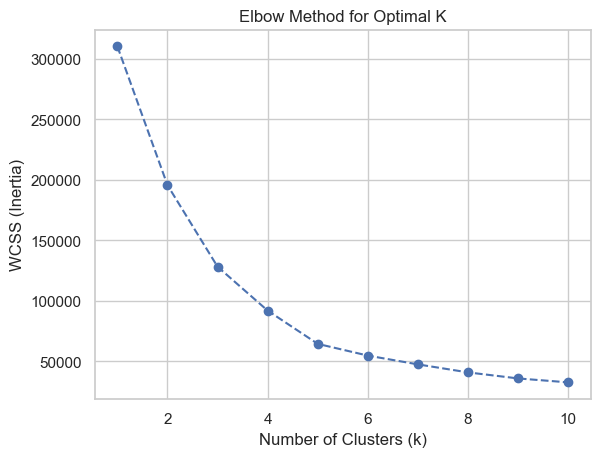

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load the dataset
filename = 'FILTERED_MASTER_ANALYTICS_23_UNIS.csv'
df = pd.read_csv(filename, low_memory=False)

# Select the core variables used for clustering
# Prestige, Course Value, Employment (WORK), and Satisfaction (Q27)
features = ['Prestige_Score', 'Course_Value_Index', 'WORK', 'Q27']
data_subset = df[features].copy()

# Pre-processing: Fill missing values with the median
data_subset = data_subset.fillna(data_subset.median())

# Standardize the data
# This ensures that Prestige (0-100) doesn't "outweigh" other decimal metrics
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_subset)

# The Elbow Method Loop (k=1 to 10)
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.show()

In [23]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load filtered data
df = pd.read_csv('FILTERED_MASTER_ANALYTICS_23_UNIS.csv', low_memory=False)

# Select the Features for Clustering
# Used outcomes, satisfaction, prestige, and custom value index
features = ['WORK', 'Q27', 'Prestige_Score', 'Course_Value_Index']

# Drop rows with missing values in these features to avoid errors
df_cluster = df.dropna(subset=features).copy()

# Scaling the Data
# K-Means is distance-based, so all features must be on the same 0-1 scale
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_cluster[features])

# Running K-Means
# Used K=4 to create 4 distinct "Strategic Categories"
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_cluster['Cluster_ID'] = kmeans.fit_predict(scaled_features)

# Interpret and Name the Clusters
# Used average scores of each cluster to assign a logical name
cluster_means = df_cluster.groupby('Cluster_ID')[features].mean()
print("Cluster Profiles:\n", cluster_means)

def name_clusters(cluster_id):
    mapping = {
        0: "Elite Academic Tier",      # High Prestige, High Outcomes
        1: "High-Value Career Hubs",   # High Employment, Moderate Prestige
        2: "Specialist & Niche",       # High Satisfaction, Moderate Outcomes
        3: "Developing/Entry Level"    # Lower scores across the 3 pillars
    }
    return mapping.get(cluster_id)

# Apply the names
df_cluster['Cluster_Category'] = df_cluster['Cluster_ID'].apply(name_clusters)

# Save the final file
df_cluster.to_csv('FINAL_CLUSTERED_LONDON_COURSES.csv', index=False)

print("\nSuccess! Final file saved as 'FINAL_CLUSTERED_LONDON_COURSES.csv'")

Cluster Profiles:
                  WORK        Q27  Prestige_Score  Course_Value_Index
Cluster_ID                                                          
0           65.200674   0.496630       79.507607           50.081541
1           64.132947  75.953794       80.272482           72.521062
2           63.920597  37.497856       17.342729           42.020414
3            1.077424  31.429858       23.713484           16.973972

Success! Final file saved as 'FINAL_CLUSTERED_LONDON_COURSES.csv'


In [26]:
import pandas as pd

# Loaded a reference file that contained both UKPRN and University Names for merging
reference_file = 'cleaned_london_enrollments_by_study_area_2020_2025.csv'
names_df = pd.read_csv(reference_file, low_memory=False)

# Create a clean Mapping (UKPRN -> University Name)
# Drop duplicates to ensure we have one unique name per UKPRN
ukprn_mapping = names_df[['UKPRN', 'HE provider']].dropna().drop_duplicates('UKPRN')

# Load the Clustered Master file
master_file = 'FINAL_CLUSTERED_LONDON_COURSES.csv'
master_df = pd.read_csv(master_file, low_memory=False)

# Merge the names into the master file
# Used a left join to keep all the cluster data and just add the names
master_with_names = pd.merge(master_df, ukprn_mapping, on='UKPRN', how='left')

# Reordered columns to put the Name at the front
cols = master_with_names.columns.tolist()
# Move 'HE provider' (index -1) to position 2
cols.insert(2, cols.pop(cols.index('HE provider')))
master_with_names = master_with_names[cols]

# Save the final version
master_with_names.to_csv('FINAL_CLUSTERED_LONDON_COURSES_WITH_NAMES.csv', index=False)

print("University names successfully mapped and saved!")

University names successfully mapped and saved!
